In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / "data" / "raw"

weather_file = list(
    RAW_DIR.glob("weather_daily_era5_*.csv")
)[-1]

df = pd.read_csv(weather_file)

df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (16800, 14)


,district,date,precipitation_sum,temperature_2m_mean,temperature_2m_max,temperature_2m_min,representative_latitude,representative_longitude,api_grid_latitude,api_grid_longitude,api_grid_elevation_m,weather_model,weather_source,timezone
0,Ampara,2024-12-30,5.6,25.9,28.5,23.6,7.124905,81.685472,7.0,81.75,48.0,era5,Open-Meteo Historical Weather API,Asia/Colombo
1,Ampara,2024-12-31,16.1,25.6,27.6,24.4,7.124905,81.685472,7.0,81.75,48.0,era5,Open-Meteo Historical Weather API,Asia/Colombo
2,Ampara,2025-01-01,26.5,25.1,26.7,24.3,7.124905,81.685472,7.0,81.75,48.0,era5,Open-Meteo Historical Weather API,Asia/Colombo
3,Ampara,2025-01-02,9.9,24.8,25.4,24.2,7.124905,81.685472,7.0,81.75,48.0,era5,Open-Meteo Historical Weather API,Asia/Colombo
4,Ampara,2025-01-03,1.7,25.8,28.2,24.1,7.124905,81.685472,7.0,81.75,48.0,era5,Open-Meteo Historical Weather API,Asia/Colombo


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16800 entries, 0 to 16799
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   district                  16800 non-null  object        
 1   date                      16800 non-null  datetime64[ns]
 2   precipitation_sum         16775 non-null  float64       
 3   temperature_2m_mean       16775 non-null  float64       
 4   temperature_2m_max        16775 non-null  float64       
 5   temperature_2m_min        16775 non-null  float64       
 6   representative_latitude   16800 non-null  float64       
 7   representative_longitude  16800 non-null  float64       
 8   api_grid_latitude         16800 non-null  float64       
 9   api_grid_longitude        16800 non-null  float64       
 10  api_grid_elevation_m      16800 non-null  float64       
 11  weather_model             16800 non-null  object        
 12  weather_source    

In [4]:
weather_columns = [
    "precipitation_sum",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min"
]

df[weather_columns].isnull().sum()

precipitation_sum      25
temperature_2m_mean    25
temperature_2m_max     25
temperature_2m_min     25
dtype: int64

In [5]:
missing_rows = df[
    df[weather_columns].isnull().any(axis=1)
]

missing_rows[
    ["district", "date"] + weather_columns
]

,district,date,precipitation_sum,temperature_2m_mean,temperature_2m_max,temperature_2m_min
671,Ampara,2026-11-01,NaN,NaN,NaN,NaN
1343,Anuradhapura,2026-11-01,NaN,NaN,NaN,NaN
2015,Badulla,2026-11-01,NaN,NaN,NaN,NaN
2687,Batticaloa,2026-11-01,NaN,NaN,NaN,NaN
3359,Colombo,2026-11-01,NaN,NaN,NaN,NaN
4031,Galle,2026-11-01,NaN,NaN,NaN,NaN
4703,Gampaha,2026-11-01,NaN,NaN,NaN,NaN
5375,Hambantota,2026-11-01,NaN,NaN,NaN,NaN
6047,Jaffna,2026-11-01,NaN,NaN,NaN,NaN
6719,Kalutara,2026-11-01,NaN,NaN,NaN,NaN


In [6]:
missing_by_date = (
    missing_rows
    .groupby("date")
    .agg(
        affected_districts=("district", "nunique"),
        missing_records=("district", "count")
    )
    .reset_index()
)

missing_by_date

,date,affected_districts,missing_records
0,2026-11-01,25,25


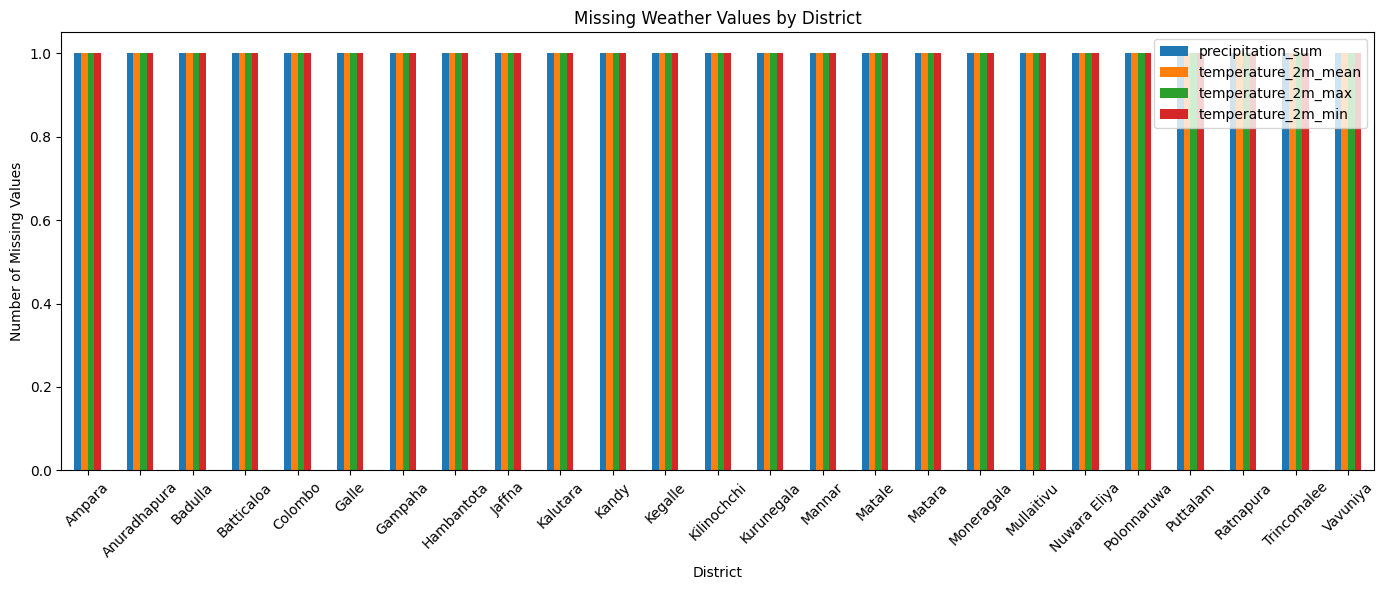

In [7]:
import matplotlib.pyplot as plt

missing_by_district = (
    df.groupby("district")[weather_columns]
    .apply(lambda x: x.isnull().sum())
)

missing_by_district.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Missing Weather Values by District")
plt.ylabel("Number of Missing Values")
plt.xlabel("District")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# Keep weather records up to 31 October 2026

df = df[df["date"] <= "2026-10-31"].copy()

df = df.reset_index(drop=True)

print("Updated dataset shape:", df.shape)
print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Number of districts:", df["district"].nunique())

Updated dataset shape: (16775, 14)
First date: 2024-12-30 00:00:00
Last date: 2026-10-31 00:00:00
Number of districts: 25


In [9]:
weather_columns = [
    "precipitation_sum",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min"
]

df[weather_columns].isna().sum()

precipitation_sum      0
temperature_2m_mean    0
temperature_2m_max     0
temperature_2m_min     0
dtype: int64

In [10]:
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

output_file = (
    PROCESSED_DIR / "weather_daily_era5_cleaned.csv"
)

df.to_csv(output_file, index=False)

print("Cleaned weather data saved:", output_file)

Cleaned weather data saved: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\weather_daily_era5_cleaned.csv
